# 01 — EDA: VN-Index daily data (Phase A)

- Objective: Clean data, calculate log returns, and describe the characteristics of returns and volatility.

- Answers: RQ1 (return characteristics) and RQ2 (how volatility changes over time).

- Structure: A1 Load → A2 Data quality check → A3 Log return → A4 Descriptive statistics → A5 Visualizations → A6 Volatility clustering → A7 Remarks

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

def find_root(start=None):
    """Auto-detect the project root directory (where src/data.py is located), independent of the working directory."""
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "src" / "data.py").exists():
            return p
    raise FileNotFoundError(
        "Project directory not found (requires src/data.py). "
        "Please open the notebook from inside the vn-index-volatility-research/ directory while preserving the folder structure."
    )


ROOT = find_root()
sys.path.insert(0, str(ROOT))
from src.data import load_vnindex, find_data_file

DATA_PATH = find_data_file(ROOT)  # defaults to data/vnindex.csv; or the single .csv file in data/
print("Reading data from:", DATA_PATH)  # <-- change file name if needed
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})


def savefig(name):
    plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")

Reading data from: D:\Uni\Time-Series_Research_Project\vn-index-volatility-research\data\vnindex.csv


## A1. Load data

In [2]:
df = load_vnindex(DATA_PATH)
print("Shape:", df.shape)
print("Date range:", df.index.min().date(), "→", df.index.max().date())
print("Unparseable dates:", df.attrs["n_bad_dates"],
      "| Duplicate dates dropped:", df.attrs["n_duplicates"],
      "| Rows with missing close dropped:", df.attrs["n_missing_close"])
display(df.head())
display(df.tail())

Shape: (5932, 6)
Date range: 2000-07-31 → 2024-12-16
Unparseable dates: 0 | Duplicate dates dropped: 0 | Rows with missing close dropped: 0


,close,open,high,low,volume,pct_change
date,,,,,,
2000-07-31,101.55,101.55,101.55,101.55,10.0,1.55
2000-08-02,103.38,103.38,103.38,103.38,NaN,1.80
2000-08-04,105.20,105.20,105.20,105.20,0.0,1.76
2000-08-07,106.92,106.92,106.92,106.92,10.0,1.63
2000-08-09,108.64,108.64,108.64,108.64,20.0,1.61


,close,open,high,low,volume,pct_change
date,,,,,,
2024-12-10,1272.07,1273.84,1277.32,1270.32,631450.0,-0.14
2024-12-11,1268.86,1273.23,1276.67,1264.15,627530.0,-0.25
2024-12-12,1267.35,1268.86,1275.64,1265.99,554120.0,-0.12
2024-12-13,1262.57,1267.35,1267.35,1260.48,478790.0,-0.38
2024-12-16,1263.79,1262.57,1267.10,1258.65,538930.0,0.10


## A2. Data Quality Investigation

In [3]:
print("Missing values per column:")
print(df.isna().sum(), "\n")

assert (df["close"] > 0).all(), "There are close prices <= 0"
print("High < Low:", int((df["high"] < df["low"]).sum()))
print("Close outside [Low, High]:",
      int(((df["close"] > df["high"]) | (df["close"] < df["low"])).sum()))

# Gap between trading days (Tet / holidays can be > 7 days)
gaps = df.index.to_series().diff().dt.days
print("\nDate gap distribution:")
print(gaps.value_counts().sort_index().head(10))
print("\nGaps > 7 days:")
display(gaps[gaps > 7].to_frame("gap_days"))

# Match the '% Change' column with calculated returns from close (detect parse/data errors)
if "pct_change" in df:
    calc = df["close"].pct_change() * 100
    diff = (calc - df["pct_change"]).abs()
    print("\nmax |% calculated − % in file|:", round(diff.max(), 4),
          "| number of days differing > 0.05 percentage points:", int((diff > 0.05).sum()))

Missing values per column:
close         0
open          0
high          0
low           0
volume        7
pct_change    0
dtype: int64 

High < Low: 0
Close outside [Low, High]: 1

Date gap distribution:
date
1.0     4500
2.0      172
3.0     1160
4.0       33
5.0       33
6.0        7
7.0        4
8.0        6
10.0      11
11.0       5
Name: count, dtype: int64

Gaps > 7 days:


,gap_days
date,
2001-01-29,10.0
2004-01-27,11.0
2005-02-14,10.0
2006-02-06,10.0
2007-02-26,11.0
2008-02-12,11.0
2009-02-02,10.0
2010-02-22,10.0
2011-02-08,11.0



max |% calculated − % in file|: 0.005 | number of days differing > 0.05 percentage points: 0


In [4]:
invalid_close = df[
    (df["close"] > df["high"]) |
    (df["close"] < df["low"])
]

print("Invalid Close observations:")
display(invalid_close)

invalid_open = df[
    (df["open"] > df["high"]) |
    (df["open"] < df["low"])
]

print("Invalid Open observations:")
display(invalid_open)

invalid_ohlc = df[
    (df["high"] < df[["open", "close"]].max(axis=1)) |
    (df["low"] > df[["open", "close"]].min(axis=1)) |
    (df["high"] < df["low"])
]

print("Total invalid OHLC rows:", len(invalid_ohlc))

Invalid Close observations:


,close,open,high,low,volume,pct_change
date,,,,,,
2005-12-20,311.83,313.66,314.22,313.66,1090.0,0.07


Invalid Open observations:


,close,open,high,low,volume,pct_change
date,,,,,,
2004-12-10,230.1,229.63,230.11,230.1,810.0,0.22


Total invalid OHLC rows: 2


In [5]:
problem_dates = [
    "2005-12-20",
    "2004-12-10"
]

for date in problem_dates:

    print(f"\n{'='*50}")
    print(f"Investigating date: {date}")

    target_date = pd.Timestamp(date)

    surrounding_data = df.loc[
        (df.index >= target_date - pd.Timedelta(days=5)) &
        (df.index <= target_date + pd.Timedelta(days=5))
    ]

    display(surrounding_data)



Investigating date: 2005-12-20


,close,open,high,low,volume,pct_change
date,,,,,,
2005-12-15,314.08,315.47,315.47,314.08,870.0,-0.27
2005-12-16,314.49,314.57,314.57,314.49,560.0,0.13
2005-12-19,311.60,314.22,314.22,311.60,920.0,-0.92
2005-12-20,311.83,313.66,314.22,313.66,1090.0,0.07
2005-12-21,310.64,310.68,310.68,310.64,3810.0,-0.38
2005-12-22,309.96,308.43,309.96,308.43,2280.0,-0.22
2005-12-23,309.14,309.67,309.67,309.14,2100.0,-0.26



Investigating date: 2004-12-10


,close,open,high,low,volume,pct_change
date,,,,,,
2004-12-06,228.93,229.59,229.59,228.93,1260.0,-0.05
2004-12-07,229.81,229.59,229.81,229.59,1650.0,0.38
2004-12-08,229.66,229.55,229.66,229.55,510.0,-0.07
2004-12-09,229.59,230.11,230.11,229.59,2000.0,-0.03
2004-12-10,230.10,229.63,230.11,230.10,810.0,0.22
2004-12-13,230.71,231.02,231.02,230.71,3000.0,0.27
2004-12-14,230.72,230.71,230.72,230.71,910.0,0.00
2004-12-15,232.06,231.53,232.06,231.53,500.0,0.58


In [6]:
# Calculate percentage change from Close
df["calculated_pct_change"] = (
    df["close"].pct_change() * 100
)

# Calculate difference from original pct_change
df["pct_change_diff"] = (
    df["calculated_pct_change"] - df["pct_change"]
).abs()

# Inspect suspicious dates
check_dates = ["2005-12-20", "2004-12-10"]

display(
    df.loc[check_dates, [
        "close",
        "pct_change",
        "calculated_pct_change",
        "pct_change_diff"
    ]]
)

# Summary of consistency
print("Maximum difference:",
      df["pct_change_diff"].max())

print("Rows with difference > 0.05 percentage points:",
      (df["pct_change_diff"] > 0.05).sum())


,close,pct_change,calculated_pct_change,pct_change_diff
date,,,,
2005-12-20,311.83,0.07,0.073813,0.003813
2004-12-10,230.10,0.22,0.222135,0.002135


Maximum difference: 0.005001497155399104
Rows with difference > 0.05 percentage points: 0


In [7]:
# Identify missing Volume
missing_volume = df[df["volume"].isna()]

print("Number of missing Volume:", len(missing_volume))

print("\nDates with missing Volume:")
display(missing_volume)

# Percentage of missing values
missing_ratio = df["volume"].isna().mean() * 100

print(f"Missing Volume ratio: {missing_ratio:.4f}%")

Number of missing Volume: 7

Dates with missing Volume:


,close,open,high,low,volume,pct_change,calculated_pct_change,pct_change_diff
date,,,,,,,,
2000-08-02,103.38,103.38,103.38,103.38,NaN,1.8,1.802068,0.002068
2002-02-15,205.20,205.20,205.20,205.20,NaN,0.0,0.000000,0.000000
2002-04-29,208.48,208.48,208.48,208.48,NaN,0.0,0.000000,0.000000
2003-01-29,172.38,172.38,172.38,172.38,NaN,0.0,0.000000,0.000000
2003-01-30,172.38,172.38,172.38,172.38,NaN,0.0,0.000000,0.000000
2003-02-06,172.38,172.38,172.38,172.38,NaN,0.0,0.000000,0.000000
2003-02-07,172.38,172.38,172.38,172.38,NaN,0.0,0.000000,0.000000


Missing Volume ratio: 0.1180%


In [8]:
missing_dates = df.index[df["volume"].isna()]

for date in missing_dates:

    print(f"\n{'='*50}")
    print(f"Missing Volume date: {date}")

    target_data = df.loc[
        (df.index >= date - pd.Timedelta(days=5)) &
        (df.index <= date + pd.Timedelta(days=5))
    ]

    display(
        target_data[
            ["open", "high", "low", "close", "volume"]
        ]
    )



Missing Volume date: 2000-08-02 00:00:00


,open,high,low,close,volume
date,,,,,
2000-07-31,101.55,101.55,101.55,101.55,10.0
2000-08-02,103.38,103.38,103.38,103.38,NaN
2000-08-04,105.20,105.20,105.20,105.20,0.0
2000-08-07,106.92,106.92,106.92,106.92,10.0



Missing Volume date: 2002-02-15 00:00:00


,open,high,low,close,volume
date,,,,,
2002-02-15,205.20,205.20,205.20,205.20,NaN
2002-02-18,202.89,202.89,202.89,202.89,60.0
2002-02-20,199.52,199.52,199.52,199.52,90.0



Missing Volume date: 2002-04-29 00:00:00


,open,high,low,close,volume
date,,,,,
2002-04-24,205.65,205.65,205.65,205.65,210.0
2002-04-25,207.06,207.06,207.06,207.06,950.0
2002-04-26,208.48,208.48,208.48,208.48,240.0
2002-04-29,208.48,208.48,208.48,208.48,NaN
2002-05-02,209.52,209.52,209.52,209.52,400.0
2002-05-03,212.95,212.95,212.95,212.95,280.0


... (4 outputs left out)


Missing Volume date: 2003-02-06 00:00:00


,open,high,low,close,volume
date,,,,,
2003-02-06,172.38,172.38,172.38,172.38,NaN
2003-02-07,172.38,172.38,172.38,172.38,NaN
2003-02-10,170.94,170.94,170.94,170.94,100.0
2003-02-11,167.59,167.59,167.59,167.59,140.0



Missing Volume date: 2003-02-07 00:00:00


,open,high,low,close,volume
date,,,,,
2003-02-06,172.38,172.38,172.38,172.38,NaN
2003-02-07,172.38,172.38,172.38,172.38,NaN
2003-02-10,170.94,170.94,170.94,170.94,100.0
2003-02-11,167.59,167.59,167.59,167.59,140.0
2003-02-12,163.91,163.91,163.91,163.91,200.0


In [9]:
volume_missing_report = pd.DataFrame({
    "missing_volume": df["volume"].isna(),
    "close": df["close"],
    "open": df["open"],
    "high": df["high"],
    "low": df["low"]
})

volume_missing_report = volume_missing_report[
    volume_missing_report["missing_volume"]
]

print("Missing Volume Summary")
print("----------------------")

print("Total missing:", len(volume_missing_report))

print(
    "Missing percentage:",
    round(df["volume"].isna().mean() * 100, 4),
    "%"
)

print("\nMissing Volume Details:")
display(volume_missing_report)

# Preserve missing values
assert df["volume"].isna().sum() == 7

print("\nVolume missing values preserved.")


Missing Volume Summary
----------------------
Total missing: 7
Missing percentage: 0.118 %

Missing Volume Details:


,missing_volume,close,open,high,low
date,,,,,
2000-08-02,True,103.38,103.38,103.38,103.38
2002-02-15,True,205.20,205.20,205.20,205.20
2002-04-29,True,208.48,208.48,208.48,208.48
2003-01-29,True,172.38,172.38,172.38,172.38
2003-01-30,True,172.38,172.38,172.38,172.38
2003-02-06,True,172.38,172.38,172.38,172.38
2003-02-07,True,172.38,172.38,172.38,172.38



Volume missing values preserved.


In [10]:
# Identify consecutive unchanged Close prices
df["unchanged_close"] = (
    df["close"].diff() == 0
)

# Find consecutive unchanged observations
df["unchanged_group"] = (
    df["unchanged_close"] !=
    df["unchanged_close"].shift()
).cumsum()

unchanged_runs = (
    df[df["unchanged_close"]]
    .groupby("unchanged_group")
    .agg(
        start_date=("close", lambda x: x.index.min()),
        end_date=("close", lambda x: x.index.max()),
        consecutive_sessions=("close", "size"),
        close_price=("close", "first")
    )
    .reset_index(drop=True)
)

unchanged_runs = unchanged_runs.sort_values(
    "consecutive_sessions",
    ascending=False
)

display(unchanged_runs.head(15))


,start_date,end_date,consecutive_sessions,close_price
3,2003-01-29,2003-02-07,4,172.38
0,2002-02-15,2002-02-15,1,205.20
1,2002-04-29,2002-04-29,1,208.48
2,2002-10-31,2002-10-31,1,177.61
4,2003-05-20,2003-05-20,1,154.18
5,2003-07-07,2003-07-07,1,152.18
6,2012-12-06,2012-12-06,1,385.69
7,2018-01-23,2018-01-23,1,1087.42


The analysis identified one extended period of unchanged closing prices from 29 January to 7 February 2003, lasting four consecutive sessions, with the VN-Index remaining at 172.38. Several other isolated unchanged-price observations were also detected. These patterns may indicate periods of limited price movement or potential data-quality issues and should be flagged for further verification rather than automatically treated as errors.

## A3. Log return
`log_return_t = log(close_t / close_{t-1})`

In [12]:
df["log_ret"] = np.log(df["close"] / df["close"].shift(1))
ret = df["log_ret"].dropna()
print("Number of return observations:", len(ret))

Number of return observations: 5931


In [13]:
print("\nLog return summary:")
print(ret.describe())

print("\nMissing log returns:", df["log_ret"].isna().sum())
print("Infinite log returns:", np.isinf(ret).sum())

print("\nFirst 5 log returns:")
display(ret.head())


Log return summary:
count    5931.000000
mean        0.000425
std         0.014439
min        -0.076557
25%        -0.005534
50%         0.000607
75%         0.007378
max         0.066561
Name: log_ret, dtype: float64

Missing log returns: 1
Infinite log returns: 0

First 5 log returns:


date
2000-08-02    0.017860
2000-08-04    0.017452
2000-08-07    0.016218
2000-08-09    0.015959
2000-08-11    0.015708
Name: log_ret, dtype: float64

The daily log returns were calculated using the natural logarithm of the ratio between consecutive closing prices. Since the first observation has no previous closing price, it produces a missing value and is excluded. The resulting dataset contains **5,931 log return observations** from the original 5,932 price records.

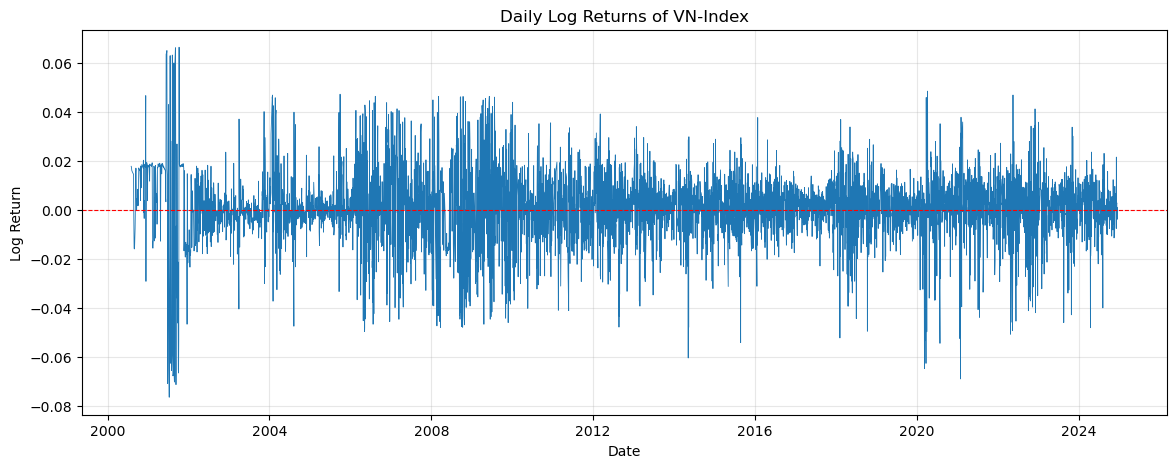

In [14]:
plt.figure(figsize=(14, 5))
plt.plot(ret.index, ret, linewidth=0.6)
plt.axhline(0, color="red", linestyle="--", linewidth=0.8)
plt.title("Daily Log Returns of VN-Index")
plt.xlabel("Date")
plt.ylabel("Log Return")
plt.grid(alpha=0.3)
plt.show()

## A4. Descriptive Statistics

In [9]:
summary = pd.Series({
    "n_obs": len(ret),
    "mean": ret.mean(),
    "std (daily)": ret.std(),
    "annualized vol (std*sqrt(252))": ret.std() * np.sqrt(252),
    "min": ret.min(),
    "max": ret.max(),
    "skewness": ret.skew(),
    "excess kurtosis": ret.kurt(),
})
display(summary.to_frame("value"))
display(ret.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).to_frame("quantile"))

jb_stat, jb_p = stats.jarque_bera(ret)
print(f"Jarque-Bera: stat={jb_stat:.1f}, p-value={jb_p:.3g}  (small p → reject hypothesis that return ~ Normal)")

print("\nTop 10 most volatile sessions:")
display(ret.abs().sort_values(ascending=False).head(10).to_frame("abs_log_ret").join(ret.rename("log_ret")))

# Volatility by year
by_year = ret.groupby(ret.index.year).agg(n="count", mean="mean", daily_std="std")
by_year["annualized_vol"] = by_year["daily_std"] * np.sqrt(252)
display(by_year.round(5))

,value
n_obs,5931.000000
mean,0.000425
std (daily),0.014439
annualized vol (std*sqrt(252)),0.229214
min,-0.076557
max,0.066561
skewness,-0.395399
excess kurtosis,3.409743


,quantile
0.01,-0.044672
0.05,-0.023320
0.25,-0.005534
0.50,0.000607
0.75,0.007378
0.95,0.022239
0.99,0.039871


Jarque-Bera: stat=3021.1, p-value=0  (small p → reject hypothesis that return ~ Normal)

Top 10 most volatile sessions:


,abs_log_ret,log_ret
date,,
2001-07-11,0.076557,-0.076557
2001-09-10,0.071407,-0.071407
2001-06-27,0.070947,-0.070947
2001-08-27,0.070344,-0.070344
2021-01-28,0.069076,-0.069076
2001-08-13,0.067801,-0.067801
2001-08-29,0.067678,-0.067678
2001-08-17,0.067519,-0.067519
2001-08-24,0.067496,-0.067496


,n,mean,daily_std,annualized_vol
date,,,,
2000,64,0.01111,0.01150,0.18261
2001,151,0.00086,0.03423,0.54337
2002,238,-0.00105,0.00871,0.13830
2003,251,-0.00037,0.00901,0.14310
2004,250,0.00144,0.01332,0.21143
2005,251,0.00100,0.00769,0.12211
2006,250,0.00358,0.02016,0.32006
2007,248,0.00084,0.01715,0.27224
2008,245,-0.00440,0.02341,0.37156


## A5. Chart

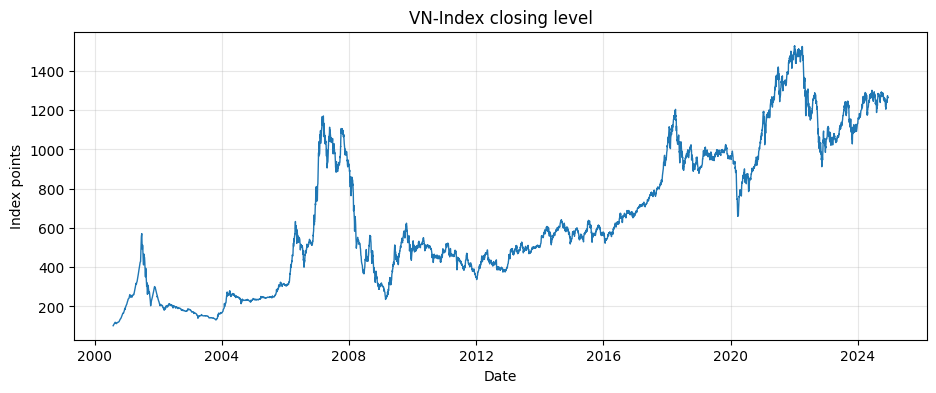

In [10]:
# 1) Closing price
fig, ax = plt.subplots()
ax.plot(df.index, df["close"], lw=1)
ax.set(title="VN-Index closing level", xlabel="Date", ylabel="Index points")
savefig("01_close.png")
plt.show()

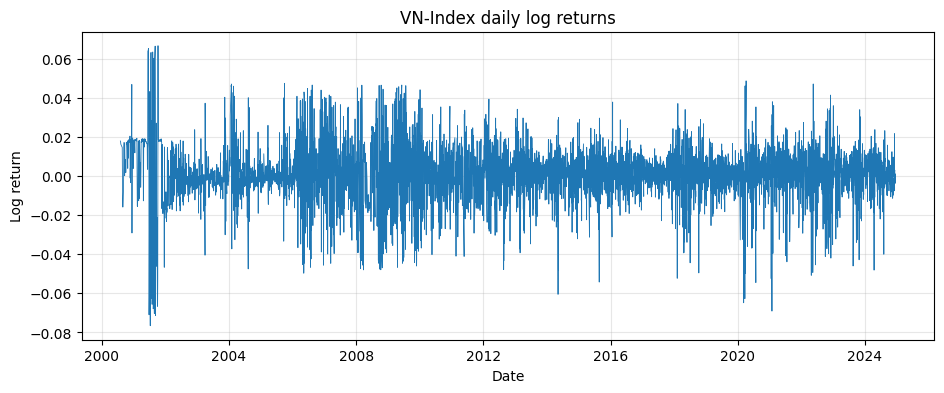

In [11]:
# 2) Log return over time
fig, ax = plt.subplots()
ax.plot(ret.index, ret, lw=0.6)
ax.set(title="VN-Index daily log returns", xlabel="Date", ylabel="Log return")
savefig("02_log_returns.png")
plt.show()

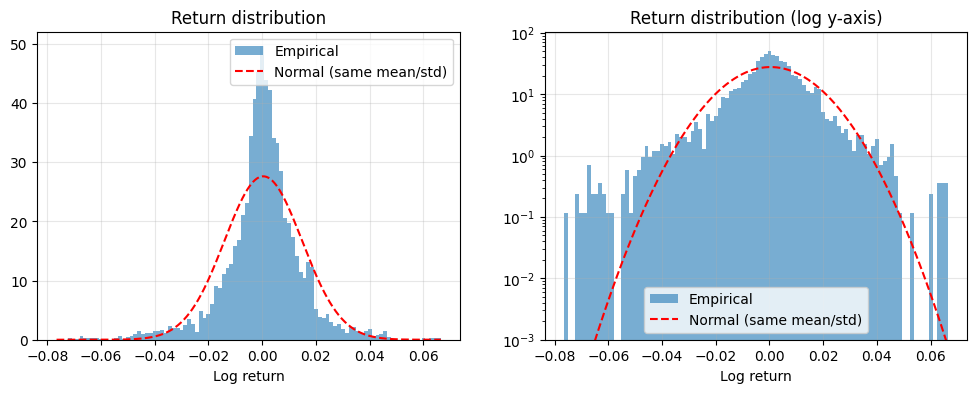

In [12]:
# 3) Return distribution vs Normal (linear and log axes to see fat tails)
x = np.linspace(ret.min(), ret.max(), 400)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, logy in zip(axes, [False, True]):
    ax.hist(ret, bins=100, density=True, alpha=0.6, label="Empirical")
    ax.plot(x, stats.norm.pdf(x, ret.mean(), ret.std()), "r--", label="Normal (same mean/std)")
    if logy:
        ax.set_yscale("log")
        ax.set_ylim(bottom=1e-3)
    ax.set(title="Return distribution" + (" (log y-axis)" if logy else ""), xlabel="Log return")
    ax.legend()
savefig("03_return_distribution.png")
plt.show()

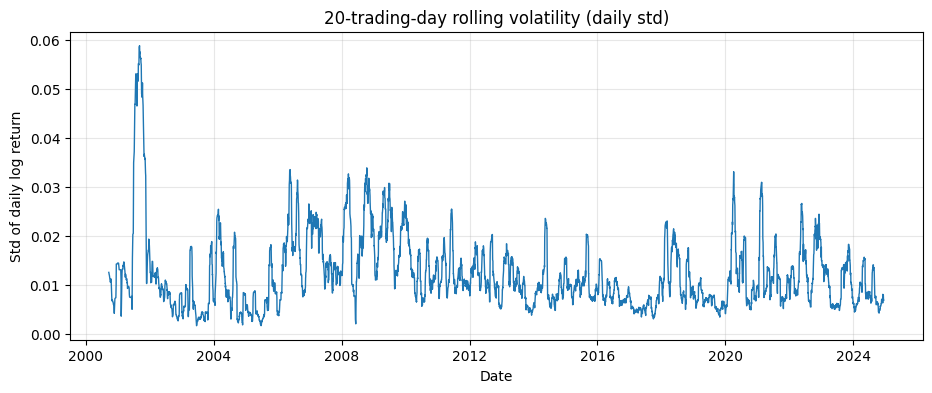

In [13]:
# 4) 20-day rolling volatility (daily std, non-annualized)
roll_vol20 = ret.rolling(20).std()
fig, ax = plt.subplots()
ax.plot(roll_vol20.index, roll_vol20, lw=1)
ax.set(title="20-trading-day rolling volatility (daily std)", xlabel="Date", ylabel="Std of daily log return")
savefig("04_rolling_vol20.png")
plt.show()

## A6. Volatility clustering

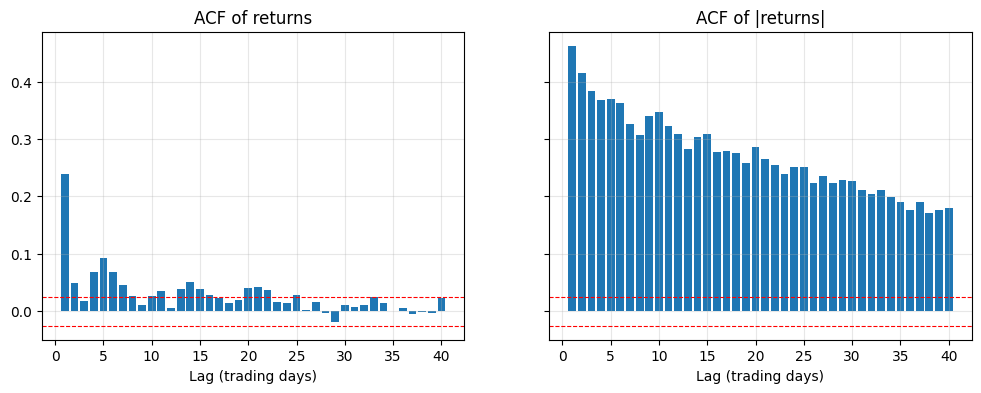

In [14]:
lags = np.arange(1, 41)
acf_ret = [ret.autocorr(l) for l in lags]
acf_abs = [ret.abs().autocorr(l) for l in lags]
band = 1.96 / np.sqrt(len(ret))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, vals, title in zip(axes, [acf_ret, acf_abs], ["ACF of returns", "ACF of |returns|"]):
    ax.bar(lags, vals)
    ax.axhline(band, color="r", ls="--", lw=0.8)
    ax.axhline(-band, color="r", ls="--", lw=0.8)
    ax.set(title=title, xlabel="Lag (trading days)")
savefig("05_acf.png")
plt.show()

## A7. Remarks (write a brief paragraph)
Use the results and charts above to address the following:
- Data: How many observations are there, what is the date range, and are there any quality issues (duplicate dates, missing values, or discrepancies between reported and calculated percentage changes)?
- RQ1: The mean return is approximately 0; what is the standard deviation? What do skewness and kurtosis indicate about fat tails? What is the conclusion of the JB test?
- RQ2: When did volatility reach high levels (see the yearly table and rolling volatility chart)? Is there volatility clustering (the ACF of |r|)?
- Modeling implication: Because volatility is persistent, recent rolling volatility will be a difficult baseline to outperform.